# windpowerlib

In [1]:
import os
import pandas as pd
import requests

from windpowerlib import ModelChain, WindTurbine, create_power_curve
from windpowerlib import data as wt

import matplotlib.pyplot as plt

In [8]:
'''
read weather data
'''

filename = './data/weather.csv'
weather_df = pd.read_csv(
    filename,
    index_col=0,
    header=[0,1]
)

weather_df.index = pd.to_datetime(
    weather_df.index, 
    utc=True
) #UTC=True (+00:00)

weather_df.index = weather_df.index.tz_convert(
        'Europe/Berlin'
)

display(weather_df)

variable_name,pressure,temperature,wind_speed,roughness_length,temperature,wind_speed
height,0,2,10,0,10,80
2010-01-01 00:00:00+01:00,98405.7,267.60,5.32697,0.15,267.57,7.80697
2010-01-01 01:00:00+01:00,98382.7,267.60,5.46199,0.15,267.55,7.86199
2010-01-01 02:00:00+01:00,98362.9,267.61,5.67899,0.15,267.54,8.59899
2010-01-01 03:00:00+01:00,98340.9,267.63,5.68466,0.15,267.56,7.89466
2010-01-01 04:00:00+01:00,98336.8,267.63,5.38084,0.15,267.61,7.57084
...,...,...,...,...,...,...
2010-12-31 19:00:00+01:00,101047.0,271.35,3.15809,0.15,271.31,5.57809
2010-12-31 20:00:00+01:00,100985.0,270.95,3.20896,0.15,270.88,5.79896
2010-12-31 21:00:00+01:00,100939.0,270.50,3.42077,0.15,270.44,5.85077


In [9]:
'''
Select wind turbine 
'''
df_wt = wt.get_turbine_types(print_out=True)

       manufacturer  turbine_type  has_power_curve has_cp_curve
0       Adwen/Areva    AD116/5000             True        False
1           Enercon    E-101/3050             True         True
2           Enercon    E-101/3500             True         True
3           Enercon    E-115/3000             True         True
4           Enercon    E-115/3200             True         True
5           Enercon    E-126/4200             True         True
6           Enercon    E-126/7500             True        False
7           Enercon    E-126/7580             True        False
8           Enercon    E-141/4200             True         True
9           Enercon      E-53/800             True         True
10          Enercon     E-70/2000             True        False
11          Enercon     E-70/2300             True         True
12          Enercon     E-82/2000             True         True
13          Enercon     E-82/2300             True         True
14          Enercon     E-82/2350       

In [12]:
df_wt.iloc[53]

'''
Rated power, 3.45 MW ; Rotor diameter, 112 m ; Market, Offshore ; Swept area, 9,853 m² ; Specific power, 350 W/m²
'''

manufacturer          Vestas
turbine_type       V112/3450
has_power_curve         True
has_cp_curve            True
Name: 53, dtype: object

In [17]:
'''
Initialize WindTurbine object
'''
vestas_v112_3450 = {
    'turbine_type':'V112/3450',
    'hub_height':119
}
vestas112 = WindTurbine(**vestas_v112_3450)
display(vestas112)

Wind turbine: V112/3450 ['nominal power=3450000.0 W', 'hub height=119 m', 'rotor diameter=112.0 m', 'power_coefficient_curve=True', 'power_curve=True']

In [20]:
'''
MpdelChain setup for Power output calculation
'''
modelchain_data = {
    'wind_speed_model': 'logarithmic',      # 'logarithmic' (default),
                                            # 'hellman' or
                                            # 'interpolation_extrapolation'
    'density_model': 'ideal_gas',           # 'barometric' (default), 'ideal_gas'
                                            #  or 'interpolation_extrapolation'
    'temperature_model': 'linear_gradient', # 'linear_gradient' (def.) or
                                            # 'interpolation_extrapolation'
    'power_output_model':
        'power_coefficient_curve',          # 'power_curve' (default) or
                                            # 'power_coefficient_curve'
    'density_correction': True,             # False (default) or True
    'obstacle_height': 0,                   # default: 0
    'hellman_exp': None}                    # None (default) or None

mc_vestas112 = ModelChain(vestas112, **modelchain_data).run_model(
    weather_df)


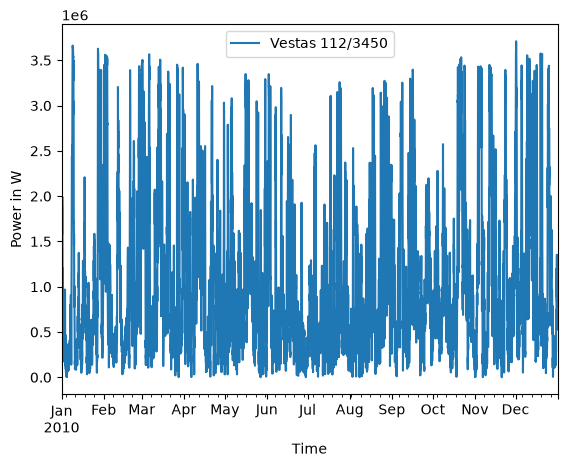

In [28]:
vestas112.power_output = mc_vestas112.power_output
vestas112.power_output.plot(legend=True, label='Vestas V112/3450')
plt.xlabel('Time')
plt.ylabel('Power in W')
plt.show()

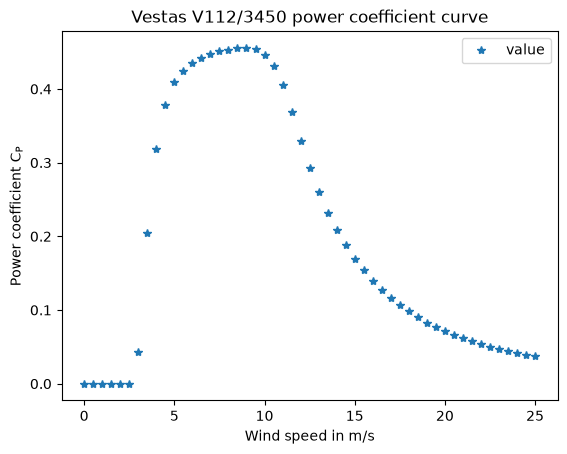

In [30]:
vestas112.power_coefficient_curve.plot(
            x='wind_speed', y='value', style='*',
            title='Vestas V112/3450 power coefficient curve')
plt.xlabel('Wind speed in m/s')
plt.ylabel('Power coefficient $\mathrm{C}_\mathrm{P}$')
plt.show()

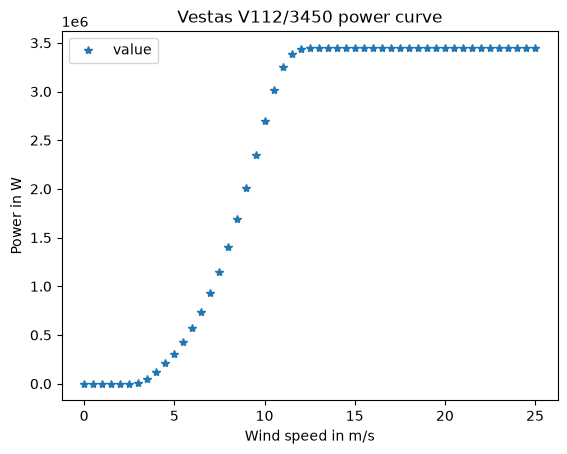

In [32]:
vestas112.power_curve.plot(
            x='wind_speed', y='value', style='*',
            title='Vestas V112/3450 power curve')
plt.xlabel('Wind speed in m/s')
plt.ylabel('Power in W')
plt.show()